# Impact of a single node

**Internship at CoMuNe Lab** · Riccardo Corte

Take one observable of the network, remove node `i`, compute it again and rank the nodes by the difference. Removing a node in message passing is `φ_i = 0`. For each node, at fixed `φ`:

- `S_on`: `S` with node `i` always present (`φ_i = 1`), and `S_off`: `S` with node `i` absent (`φ_i = 0`);
- `D_i = S_on − S_off`. In the exact process `S` is linear in `φ_i`, `S = φ_i S_on + (1 − φ_i) S_off`, so the damage of the loss is `φ D_i`, the gain of protecting it `(1 − φ) D_i`, and `D_i = ∂S/∂φ_i`;
- **indirect damage** `I_i = D_i − s_i^on / N`: `D_i` without the node itself, that is, the other nodes that lose the giant component because of `i`.

## 0. Setup

In [1]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import scipy.sparse as sp
from pathlib import Path
from numba import njit
from scipy.stats import spearmanr

from mp import (struttura_mp, message_passing_veloce, curva_mp, struttura_mc, mc_1run_veloce, phi_ibrido, matrice_G, matrice_M,
                lambda_max, power_law, fit_soglia, _lcc_unionfind)

cartella_dati = Path("../data/raw/zitnik2019_treeoflife/treeoflife.interactomes")
cartella_ris = Path("risultati/08")
cartella_ris.mkdir(exist_ok=True)

# --- parameters ---
N_big = 1000        # number of nodes of each graph
n_blocchi = 4       # communities of the block model, N_big / n_blocchi nodes each
k_dentro = 2.8      # mean number of links of a node inside its own community
k_fuori = 0.2       # mean number of links of a node towards the other communities
k_er = 3            # mean degree of the Erdos-Renyi graph
m_ba = 3            # links brought by each new node in the Barabasi-Albert graph

# link probabilities of the block model: with n nodes per community, a node has n - 1 possible
# partners inside and N_big - n outside, so p = (mean number of links) / (possible partners)
n_com = N_big // n_blocchi
p_dentro = k_dentro / (n_com - 1)
p_fuori = k_fuori / (N_big - n_com)

# --- the three graphs ---
grafi = {
    "communities": nx.stochastic_block_model(
        [N_big // n_blocchi] * n_blocchi,
        [[p_dentro if a == b else p_fuori for b in range(n_blocchi)] for a in range(n_blocchi)],
        seed=1),
    "Erdos-Renyi": nx.gnp_random_graph(N_big, k_er / (N_big - 1), seed=1),
    "Barabasi-Albert": nx.barabasi_albert_graph(N_big, m_ba, seed=1),
}

specie = {1148: "Synechocystis", 85962: "H. pylori", 5833: "P. falciparum", 511145: "E. coli"}
reti = dict(grafi)
reti.update({nome: nx.read_edgelist(cartella_dati / f"{sid}.txt") for sid, nome in specie.items()})
gradi = {nome: dict(g.degree) for nome, g in reti.items()}
betw = {nome: nx.betweenness_centrality(g) for nome, g in reti.items()}

## 1. Scan with message passing

`D_i` and `I_i` for all the nodes, at `φ = 0.1, 0.2, 0.4, 0.7`, two solves per node. `S_off` starts from the messages of the whole network (warm start: with a node removed the messages can only go down). `S_on` starts from `t = 1`, because `t = 0` is a fixed point and the iteration would stay there below the threshold. Below the threshold of the network `D_i` is zero for almost all the nodes. Saved in `risultati/08/impatto_mp.csv` after each network.

In [2]:
def impatto_nodi(g, phi, struttura):
    """S_on, S_off and s_i^on of every node, in the order of the nodes of struttura; also the unconverged solves."""
    nodi = struttura[1]
    S_0, _, t_0, _, _ = message_passing_veloce(g, phi, struttura=struttura)
    phi_n = {n: phi for n in nodi}
    S_on, S_off, s_on = np.zeros(len(nodi)), np.zeros(len(nodi)), np.zeros(len(nodi))
    non_convergenti = 0
    for a, n in enumerate(nodi):
        phi_n[n] = 0.0
        S_off[a], _, _, _, ok_off = message_passing_veloce(g, phi_n, t0=t_0, struttura=struttura)
        phi_n[n] = 1.0
        S_on[a], s, _, _, ok_on = message_passing_veloce(g, phi_n, struttura=struttura)
        s_on[a] = s[a]
        phi_n[n] = phi
        non_convergenti += (not ok_off) + (not ok_on)
    return S_0, S_on, S_off, s_on, non_convergenti


valori_phi = [0.1, 0.2, 0.4, 0.7]


def phi_rete(nome, phi):
    """P. falciparum has a separate component of 7 nodes all linked together, with 1/lambda = 0.2 exactly: at phi = 0.2
    the messages there do not converge in max_iter, so this network uses 0.21 in place of 0.2."""
    return 0.21 if nome == "P. falciparum" and phi == 0.2 else phi


file_mp = cartella_ris / "impatto_mp.csv"
impatto = pd.read_csv(file_mp, dtype={"node": str}) if file_mp.exists() else pd.DataFrame(columns=["network"])
strutture = {nome: struttura_mp(g) for nome, g in reti.items()}
for nome, g in reti.items():
    if nome in set(impatto["network"]):
        continue
    t0 = time.time()
    N = g.number_of_nodes()
    pezzi = []
    for phi in [phi_rete(nome, p) for p in valori_phi]:
        S_0, S_on, S_off, s_on, nc = impatto_nodi(g, phi, strutture[nome])
        if nc:
            print(f"{nome}, phi = {phi}: {nc} solves not converged")
        pezzi.append(pd.DataFrame({"network": nome, "phi": phi, "node": [str(n) for n in strutture[nome][1]], "S0": S_0,
                                   "D": S_on - S_off, "I": S_on - S_off - s_on / N,
                                   "degree": [gradi[nome][n] for n in strutture[nome][1]],
                                   "betweenness": [betw[nome][n] for n in strutture[nome][1]]}))
    impatto = pd.concat([impatto] + pezzi, ignore_index=True)
    impatto.to_csv(file_mp, index=False)
    print(f"{nome}: {time.time() - t0:.0f} s")

E. coli: 2518 s


In [3]:
# check on the linearity: S against phi S_on + (1 - phi) S_off, on the 10 highest-degree nodes of each protein network
righe = []
for nome in specie.values():
    g, struttura = reti[nome], strutture[nome]
    for phi in [phi_rete(nome, p) for p in valori_phi]:
        S_0 = message_passing_veloce(g, phi, struttura=struttura)[0]
        phi_n = {n: phi for n in struttura[1]}
        for n in sorted(g.nodes, key=gradi[nome].get, reverse=True)[:10]:
            phi_n[n] = 1.0
            on = message_passing_veloce(g, phi_n, struttura=struttura)[0]
            phi_n[n] = 0.0
            off = message_passing_veloce(g, phi_n, struttura=struttura)[0]
            phi_n[n] = phi
            righe.append({"network": nome, "phi": phi, "S - mix": S_0 - (phi * on + (1 - phi) * off),
                          "D+ / D-": (on - S_0) / (S_0 - off) if S_0 - off > 1e-12 else np.nan, "(1-phi)/phi": (1 - phi) / phi})
controllo = pd.DataFrame(righe)
display(controllo.groupby(["network", "phi"]).agg(max_abs=("S - mix", lambda x: x.abs().max()), ratio_min=("D+ / D-", "min"),
                                                 ratio_max=("D+ / D-", "max"), expected=("(1-phi)/phi", "first")).round(5))

max_abs  ratio_min  ratio_max  expected
network       phi                                          
E. coli       0.10  0.00003    8.39935    8.90882   9.00000
              0.20  0.00003    3.84329    3.99124   4.00000
              0.40  0.00001    1.47977    1.49960   1.50000
              0.70  0.00000    0.42773    0.42857   0.42857
H. pylori     0.10  0.00031    4.66191   15.63884   9.00000
              0.20  0.00026    3.03507    3.86935   4.00000
              0.40  0.00008    1.36962    1.49963   1.50000
              0.70  0.00006    0.40402    0.42857   0.42857
P. falciparum 0.10  0.00018    5.73594    8.12289   9.00000
              0.21  0.00008    3.36304    3.69564   3.76190
              0.40  0.00001    1.44145    1.49967   1.50000
              0.70  0.00001    0.42117    0.42857   0.42857
Synechocystis 0.10  0.00012    5.70308   10.39222   9.00000
              0.20  0.00015    2.66858    3.93968   4.00000
              0.40  0.00013    1.38830    1.49946   1.50000
              0.70  0.00004    0.41590    0.42857   0.42857

### 1.1 Who has the largest indirect damage

For each network and `φ`: the Spearman correlation of `I_i` with degree and betweenness, and the shared nodes among the 30 with the largest `I_i` and the 30 with the largest degree and betweenness. Then how the ranking changes with `φ`.

In [4]:
righe = []
for (nome, phi), t in impatto.groupby(["network", "phi"], sort=False):
    if t["S0"].iloc[0] < 1e-6:
        continue
    primi = set(t.nlargest(30, "I")["node"])
    righe.append({"network": nome, "phi": phi, "S": t["S0"].iloc[0], "max I": t["I"].max(), "mean I": t["I"].mean(),
                  "mean D": t["D"].mean(), "Spearman degree": spearmanr(t["I"], t["degree"]).statistic,
                  "Spearman betweenness": spearmanr(t["I"], t["betweenness"]).statistic,
                  "top 30 degree": len(primi & set(t.nlargest(30, "degree")["node"])),
                  "top 30 betweenness": len(primi & set(t.nlargest(30, "betweenness")["node"]))})
display(pd.DataFrame(righe).round(5))

righe = []
for nome, t in impatto.groupby("network", sort=False):
    per_phi = {phi: q.set_index("node")["I"] for phi, q in t.groupby("phi") if q["S0"].iloc[0] >= 1e-6}
    chiavi = sorted(per_phi)
    for a, b in zip(chiavi, chiavi[1:]):
        righe.append({"network": nome, "phi": a, "next phi": b, "Spearman": spearmanr(per_phi[a], per_phi[b].reindex(per_phi[a].index)).statistic,
                      "shared top 30": len(set(per_phi[a].nlargest(30).index) & set(per_phi[b].nlargest(30).index))})
display(pd.DataFrame(righe).round(3))

,network,phi,S,max I,mean I,mean D,Spearman degree,Spearman betweenness,top 30 degree,top 30 betweenness
0,communities,0.40,0.13275,0.00944,0.00144,0.00177,0.94169,0.89458,19,14
1,communities,0.70,0.58103,0.00310,0.00047,0.00130,0.80720,0.74548,9,4
2,Erdos-Renyi,0.40,0.11764,0.01231,0.00156,0.00185,0.92478,0.92567,20,20
3,Erdos-Renyi,0.70,0.57000,0.00290,0.00049,0.00130,0.82516,0.79588,7,8
4,Barabasi-Albert,0.10,0.00351,0.02265,0.00041,0.00045,0.67769,0.73831,27,26
5,Barabasi-Albert,0.20,0.08708,0.01687,0.00065,0.00109,0.95913,0.90876,30,29
6,Barabasi-Albert,0.40,0.33538,0.00818,0.00043,0.00127,0.94147,0.81903,25,25
7,Barabasi-Albert,0.70,0.69040,0.00241,0.00010,0.00109,0.90797,0.78939,24,24
8,Synechocystis,0.10,0.01062,0.00515,0.00009,0.00015,0.93426,0.74527,15,12
9,Synechocystis,0.20,0.06649,0.00692,0.00019,0.00034,0.94506,0.81948,11,25


,network,phi,next phi,Spearman,shared top 30
0,communities,0.40,0.70,0.629,3
1,Erdos-Renyi,0.40,0.70,0.629,2
2,Barabasi-Albert,0.10,0.20,0.620,27
3,Barabasi-Albert,0.20,0.40,0.871,25
4,Barabasi-Albert,0.40,0.70,0.968,26
5,Synechocystis,0.10,0.20,0.915,9
6,Synechocystis,0.20,0.40,0.815,20
7,Synechocystis,0.40,0.70,0.878,20
8,H. pylori,0.10,0.20,0.919,6
9,H. pylori,0.20,0.40,0.827,20


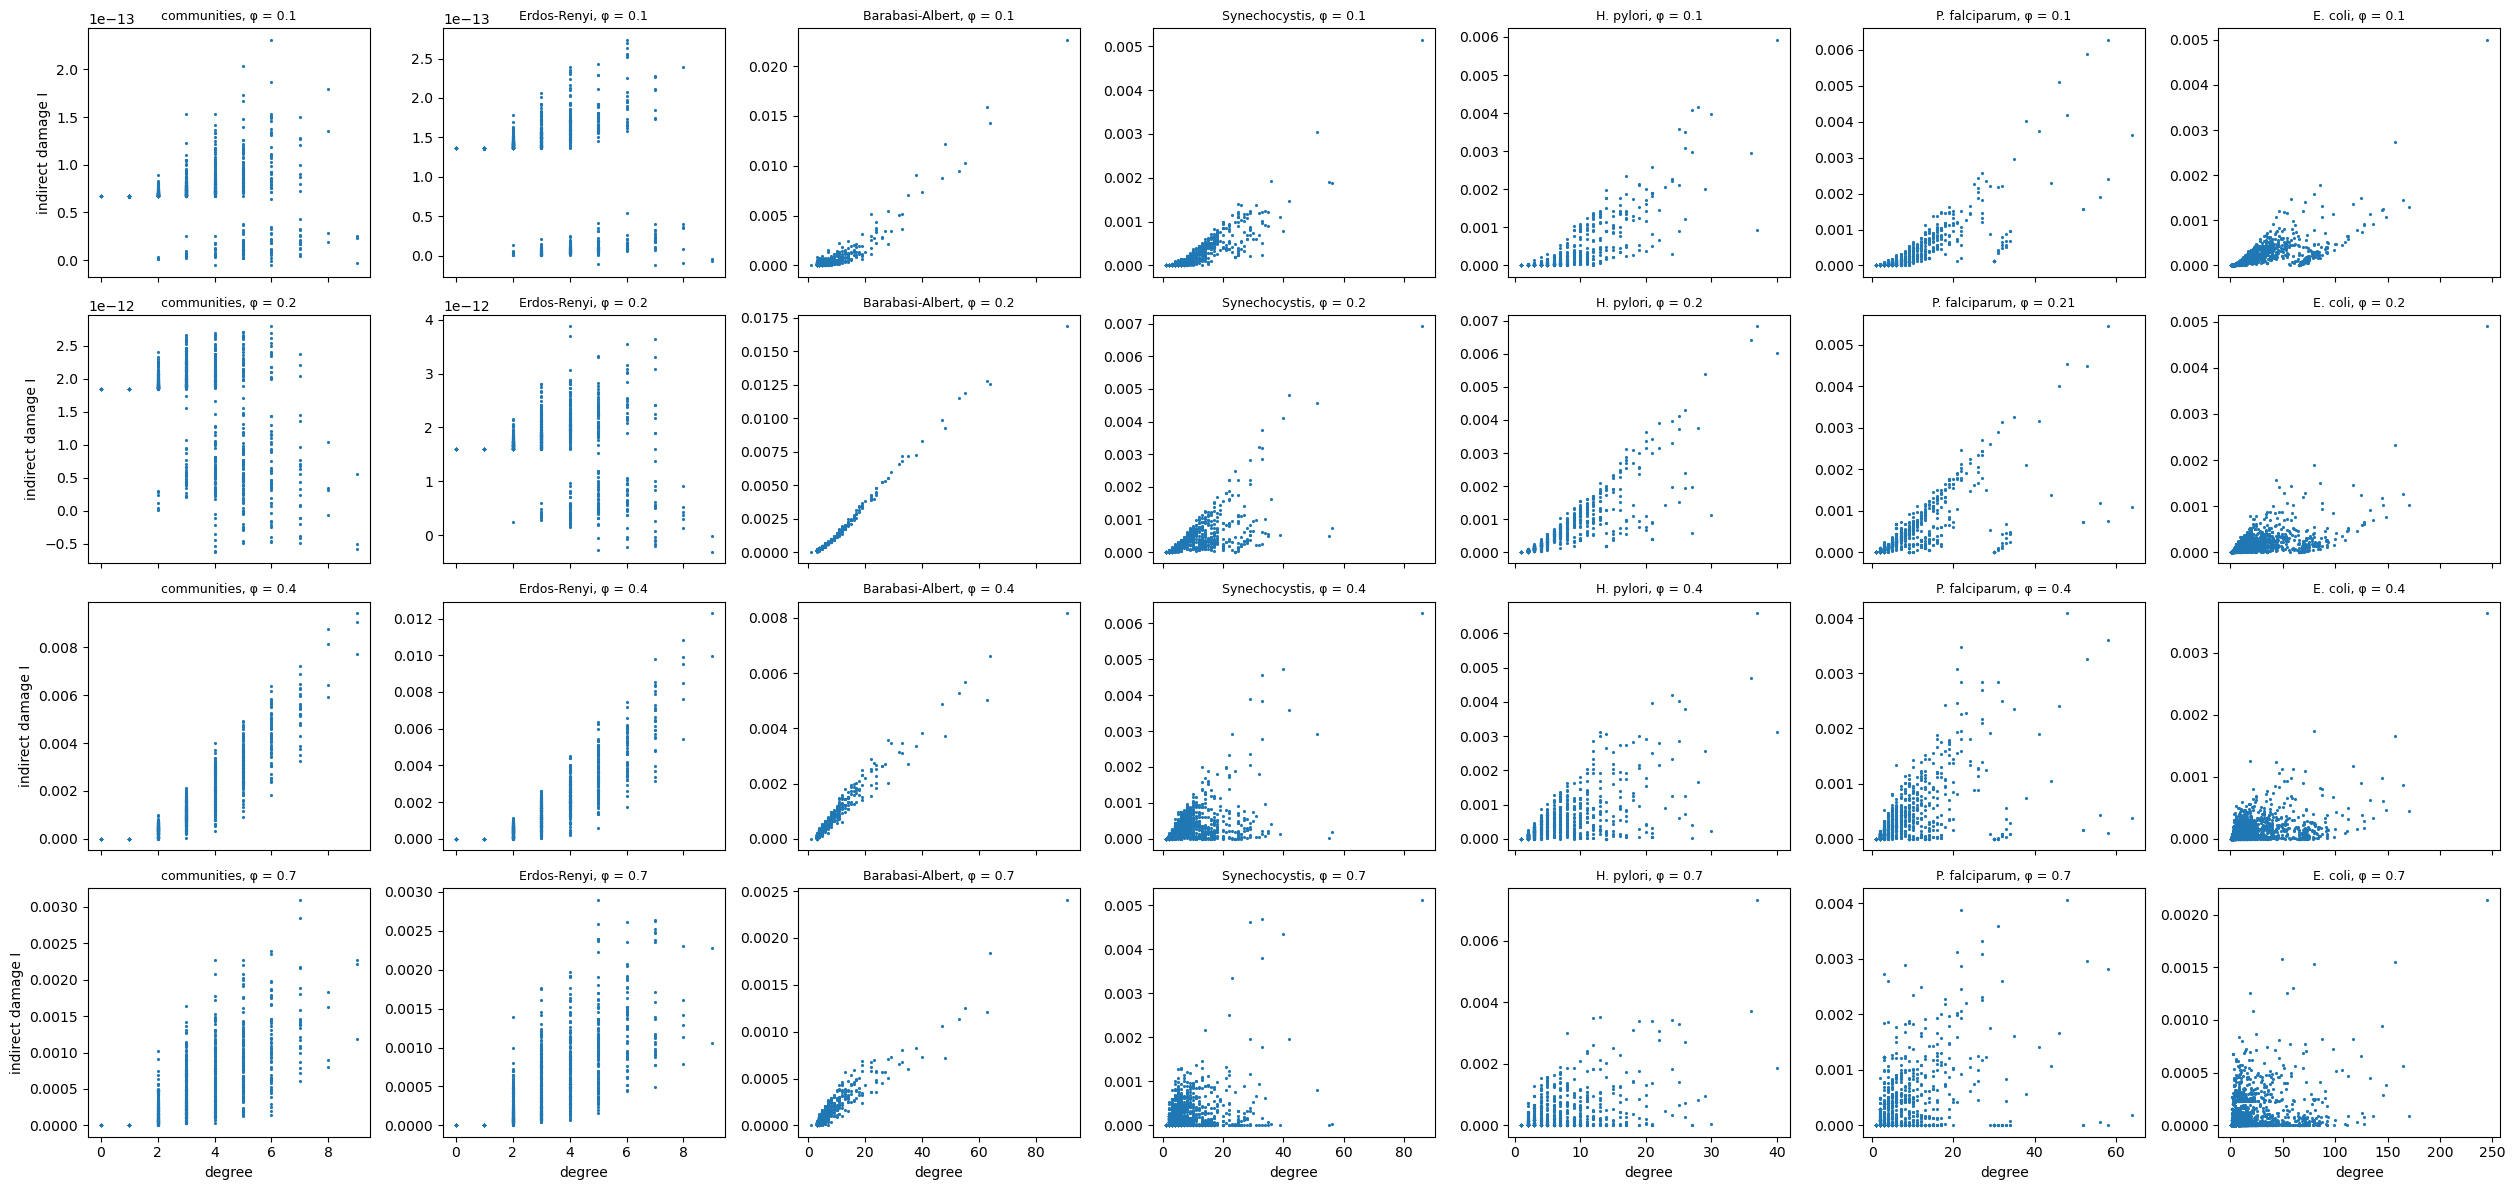

In [5]:
# indirect damage against degree, one column per network, one row per phi
nomi = list(reti)
fig, assi = plt.subplots(len(valori_phi), len(nomi), figsize=(3.6 * len(nomi), 3 * len(valori_phi)), sharex="col")
for r, phi in enumerate(valori_phi):
    for col, nome in enumerate(nomi):
        t = impatto[(impatto["network"] == nome) & (impatto["phi"] == phi_rete(nome, phi))]
        assi[r, col].plot(t["degree"], t["I"], ".", ms=2.5)
        assi[r, col].set_title(f"{nome}, φ = {phi_rete(nome, phi)}", fontsize=9)
    assi[r, 0].set_ylabel("indirect damage I")
for ax in assi[-1]:
    ax.set_xlabel("degree")
plt.tight_layout()
plt.show()

#### Comment on section 1

**Linearity.** On the 10 highest-degree nodes of each protein network, `S` differs from `φ S_on + (1 − φ) S_off` by at most 3·10⁻⁴: in message passing too `S` is, to this precision, a straight line in `φ_i`, so `D_i` is its slope. The ratio `(S − S_off)/(S_on − S)`, which for a straight line is `(1 − φ)/φ`, matches it at `φ = 0.4` and `0.7`; at `φ = 0.1` it scatters (4.7 to 15.6 against 9) because there the differences are of order 10⁻⁴.

**Who has the largest indirect damage.** On Barabási-Albert `I_i` follows the degree: at `φ = 0.2` the top 30 by `I` share 30 nodes with the top 30 by degree and 29 with the top 30 by betweenness, and the Spearman correlation with degree is 0.96. On the proteins degree is not enough: at `φ = 0.2` and `0.4` the top 30 by `I` share 7 to 15 nodes with the top 30 by degree and 17 to 25 with the top 30 by betweenness. In the plots, nodes with the same degree go from no indirect damage to about 10 nodes lost, and some large hubs do almost none. On the proteins the most damaging nodes are bridges more than hubs, and betweenness finds them better than degree, as for `S` at fixed `φ` in notebook 06.

**Size and stability.** At `φ = 0.2` the most damaging protein disconnects 8 to 15 other proteins (`I N`). On the proteins the order of the nodes changes little with `φ` (Spearman 0.82-0.96 between consecutive values), while the top 30 change more (6 to 24 nodes in common). On Erdős-Rényi and communities the top 30 at `φ = 0.4` and `0.7` share only 2-3 nodes.

## 2. Check against Monte Carlo, node by node

Two independent Monte Carlo estimates of `S` have an error as large as `D_i`. Here the runs are paired: the same draw of the other nodes, with node `i` present and absent, so the error is that of the difference. 2000 pairs per node, all the nodes. `S` Monte Carlo is the largest component only, so `I_i` subtracts the probability that `i` belongs to it when present. Synechocystis at `φ = 0.1, 0.2, 0.4`; Barabási-Albert at `φ = 0.2, 0.4` and Erdős-Rényi at `φ = 0.5, 0.7` as references. Saved in `risultati/08/impatto_mc.csv` after each case.

In [6]:
@njit(cache=True)
def _lcc_con_nodo(presente, u, v, j):
    """Size of the largest component of the present nodes, and whether node j belongs to it (as _lcc_unionfind in mp.py)."""
    N = presente.shape[0]
    padre = np.arange(N)
    dim = np.ones(N, np.int64)
    for a in range(u.shape[0]):
        x, y = u[a], v[a]
        if not (presente[x] and presente[y]):
            continue
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        while padre[y] != y:
            padre[y] = padre[padre[y]]
            y = padre[y]
        if x != y:
            if dim[x] < dim[y]:
                x, y = y, x
            padre[y] = x
            dim[x] += dim[y]
    x = j
    while padre[x] != x:
        x = padre[x]
    piu_grande = 0
    for i in range(N):
        if presente[i] and padre[i] == i and dim[i] > piu_grande:
            piu_grande = dim[i]
    return piu_grande, dim[x] == piu_grande


@njit(cache=True)
def mc_coppie(u, v, N, phi, num_coppie, seme):
    """For every node: mean and std of (LCC with the node - LCC without it) over paired draws, in nodes,
    and the probability that the node is in the LCC when present."""
    np.random.seed(seme)
    media, var, dentro = np.zeros(N), np.zeros(N), np.zeros(N)
    for j in range(N):
        for _ in range(num_coppie):
            presente = np.random.random(N) < phi
            presente[j] = True
            con, in_lcc = _lcc_con_nodo(presente, u, v, j)
            presente[j] = False
            d = con - _lcc_unionfind(presente, u, v)
            media[j] += d
            var[j] += d * d
            dentro[j] += in_lcc
    media /= num_coppie
    return media, np.sqrt(var / num_coppie - media ** 2), dentro / num_coppie


casi_mc = [("Synechocystis", 0.1), ("Synechocystis", 0.2), ("Synechocystis", 0.4), ("Barabasi-Albert", 0.2),
           ("Barabasi-Albert", 0.4), ("Erdos-Renyi", 0.5), ("Erdos-Renyi", 0.7)]
num_coppie = 2000
file_mc = cartella_ris / "impatto_mc.csv"
impatto_mc = pd.read_csv(file_mc, dtype={"node": str}) if file_mc.exists() else pd.DataFrame(columns=["network", "phi"])
for caso, (nome, phi) in enumerate(casi_mc):
    if ((impatto_mc["network"] == nome) & (impatto_mc["phi"] == phi)).any():
        continue
    t0 = time.time()
    nodi, u, v = struttura_mc(reti[nome])
    N = len(nodi)
    media, std, dentro = mc_coppie(u, v, N, phi, num_coppie, 80 + caso)
    q = pd.DataFrame({"network": nome, "phi": phi, "node": [str(n) for n in nodi], "D MC": media / N,
                      "sem": std / N / np.sqrt(num_coppie), "I MC": (media - dentro) / N})
    impatto_mc = pd.concat([impatto_mc, q], ignore_index=True)
    impatto_mc.to_csv(file_mc, index=False)
    print(f"{nome}, phi = {phi}: {time.time() - t0:.0f} s")

/tmp/ipykernel_3016306/588472028.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  impatto_mc = pd.concat([impatto_mc, q], ignore_index=True)


Synechocystis, phi = 0.1: 722 s
Synechocystis, phi = 0.2: 626 s


Synechocystis, phi = 0.4: 694 s


Barabasi-Albert, phi = 0.2: 122 s
Barabasi-Albert, phi = 0.4: 147 s


Erdos-Renyi, phi = 0.5: 133 s


Erdos-Renyi, phi = 0.7: 173 s


,network,phi,S,Spearman D,Spearman I,"shared top 30, I","D MP / D MC, top 30 degree","D MP / D MC, all",median sem
0,Synechocystis,0.1,0.0106,0.9491,0.7643,20,1.8086,2.3698,0.0000
1,Synechocystis,0.2,0.0665,0.9306,0.8709,22,0.6195,0.9891,0.0000
2,Synechocystis,0.4,0.2610,0.9322,0.9202,27,0.8564,0.9891,0.0000
3,Barabasi-Albert,0.2,0.0871,0.9836,0.9678,29,0.9145,0.9915,0.0000
4,Barabasi-Albert,0.4,0.3354,0.9838,0.9957,29,0.9811,0.9949,0.0000
5,Erdos-Renyi,0.5,0.2874,0.9968,0.9912,28,0.9209,0.9518,0.0001
6,Erdos-Renyi,0.7,0.5700,0.9988,0.9948,29,0.9972,0.9975,0.0000


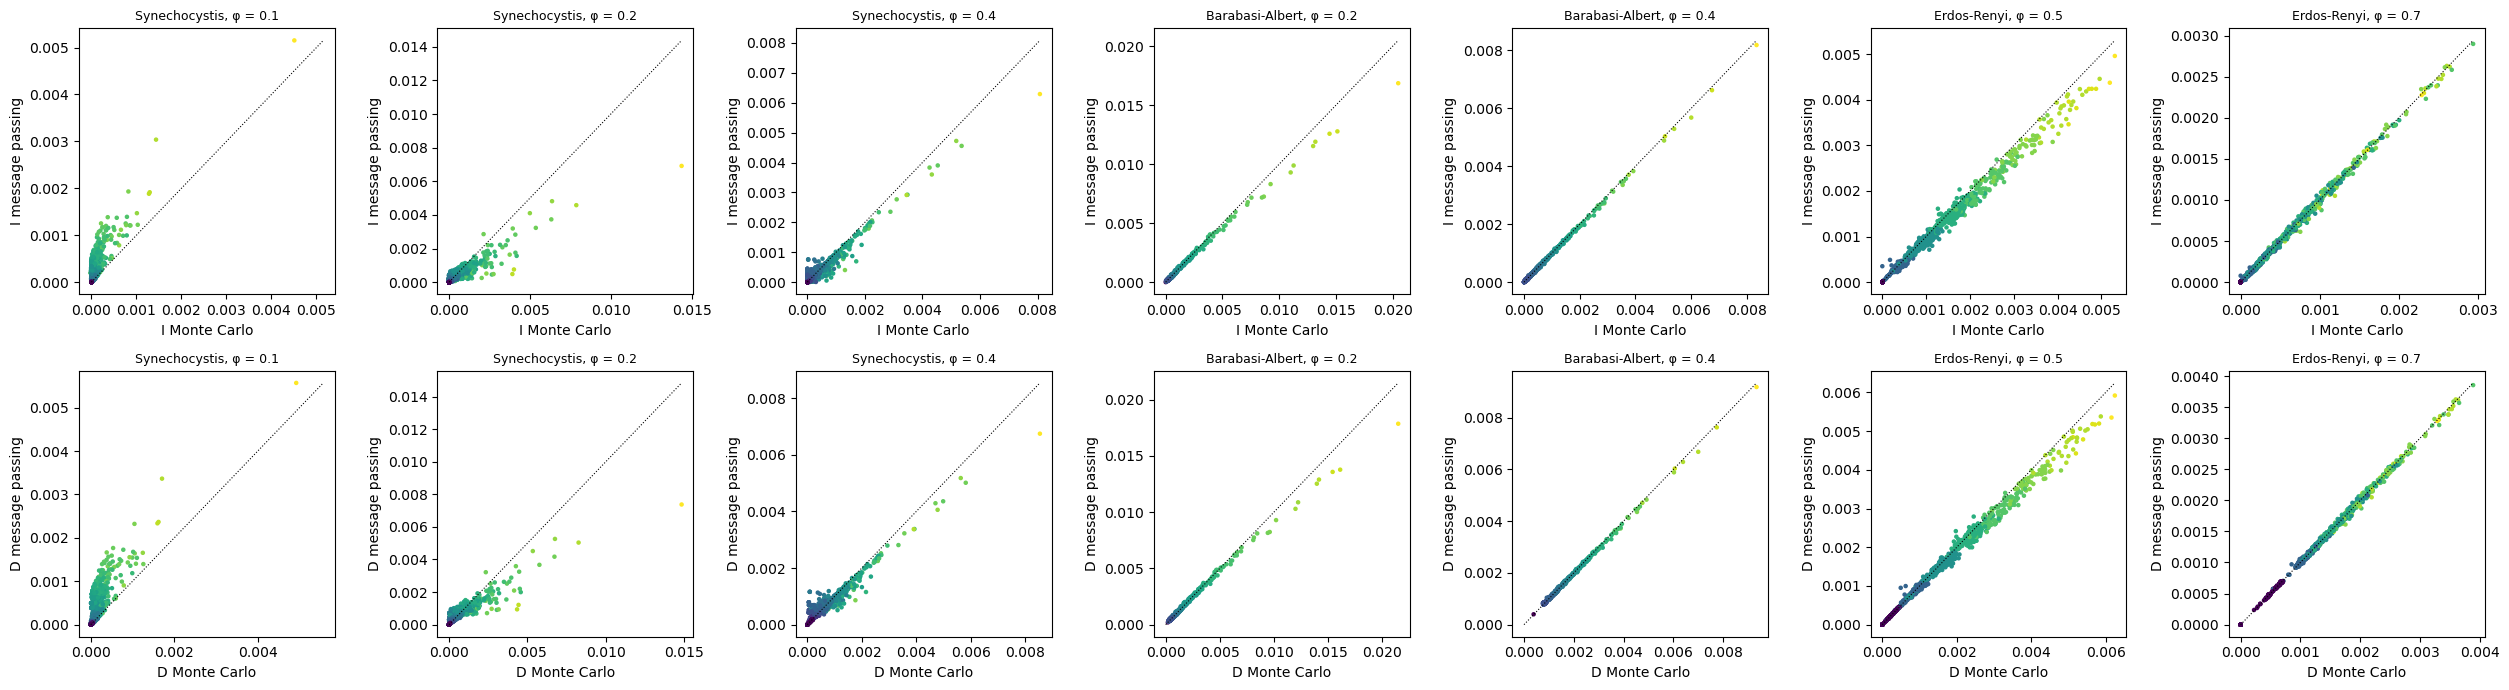

In [7]:
# phi of Erdos-Renyi not in the scan of section 1: message passing computed here for the cases missing
mancanti = []
for nome, phi in casi_mc:
    if not ((impatto["network"] == nome) & (impatto["phi"] == phi)).any():
        S_0, S_on, S_off, s_on, _ = impatto_nodi(reti[nome], phi, strutture[nome])
        N = reti[nome].number_of_nodes()
        mancanti.append(pd.DataFrame({"network": nome, "phi": phi, "node": [str(n) for n in strutture[nome][1]], "S0": S_0,
                                      "D": S_on - S_off, "I": S_on - S_off - s_on / N,
                                      "degree": [gradi[nome][n] for n in strutture[nome][1]],
                                      "betweenness": [betw[nome][n] for n in strutture[nome][1]]}))
impatto_tutti = pd.concat([impatto] + mancanti, ignore_index=True) if mancanti else impatto

confronto = impatto_mc.merge(impatto_tutti, on=["network", "phi", "node"])
righe = []
for (nome, phi), t in confronto.groupby(["network", "phi"], sort=False):
    hub = t.nlargest(30, "degree")
    righe.append({"network": nome, "phi": phi, "S": t["S0"].iloc[0],
                  "Spearman D": spearmanr(t["D"], t["D MC"]).statistic, "Spearman I": spearmanr(t["I"], t["I MC"]).statistic,
                  "shared top 30, I": len(set(t.nlargest(30, "I")["node"]) & set(t.nlargest(30, "I MC")["node"])),
                  "D MP / D MC, top 30 degree": hub["D"].sum() / hub["D MC"].sum(), "D MP / D MC, all": t["D"].sum() / t["D MC"].sum(),
                  "median sem": t["sem"].median()})
display(pd.DataFrame(righe).round(4))

casi = list(confronto.groupby(["network", "phi"], sort=False))
fig, assi = plt.subplots(2, len(casi), figsize=(3.6 * len(casi), 7))
for col, ((nome, phi), t) in enumerate(casi):
    for r, (a, b, nome_y) in enumerate([("I", "I MC", "I"), ("D", "D MC", "D")]):
        ax = assi[r, col]
        ax.scatter(t[b], t[a], c=np.log10(t["degree"].clip(lower=1)), s=5, cmap="viridis")
        lim = max(t[a].max(), t[b].max())
        ax.plot([0, lim], [0, lim], "k:", lw=0.8)
        ax.set_xlabel(f"{nome_y} Monte Carlo")
        ax.set_ylabel(f"{nome_y} message passing")
        ax.set_title(f"{nome}, φ = {phi}", fontsize=9)
plt.tight_layout()
plt.show()

#### Comment on section 2

Pairing works: the median standard error of `D_i` Monte Carlo is of order 10⁻⁵-10⁻⁴, at most about 0.1 nodes.

**Order.** Message passing ranks the nodes as Monte Carlo does: Spearman of `D_i` 0.93-0.95 on Synechocystis and 0.98-1.00 on Barabási-Albert and Erdős-Rényi; for `I_i` 0.76 at `φ = 0.1` and 0.87-0.92 above.

**Size.** On Barabási-Albert and Erdős-Rényi, locally tree-like networks, the two agree in size too (ratio of the means 0.92-1.00 on the top 30, 0.95-1.00 on all the nodes). On Synechocystis the size of the most important nodes is wrong in opposite directions depending on `φ`: on the top 30 by degree message passing gives 1.81 times Monte Carlo at `φ = 0.1`, 0.62 at `φ = 0.2` and 0.86 at `φ = 0.4`. The two methods see the giant component appear at different `φ` (notebook 06: 0.04 for message passing, 0.20 for Monte Carlo). At `φ = 0.1` message passing already sees a giant component around the hubs, and losing a hub breaks it, while in the real process there are only small pieces: message passing overestimates. At `φ = 0.2` the real network is just forming its giant component, held together by a few hubs, and losing one splits it, while for message passing the component is already solid: message passing underestimates. Higher up both are above the threshold and get closer. On all the nodes the ratio is 2.37 at `φ = 0.1` and 0.99 above. Message passing is good for ranking the nodes, not for the size of their impact near the threshold.

## 3. Impact on the threshold: `Δφ_c` against `Δφ_fit`

`Δφ_c`: change of `1/λ_max` when node `i` is removed, for all the nodes (`φ_i = 0` zeroes the rows of `G` of the messages read by `i`). `Δφ_fit`: change of the operational threshold of notebook 07 (power law, window `0.05 ≤ S ≤ 0.8`), message passing only: its result has no noise, so small differences are measured. It needs a whole curve per node, so here on 90 nodes per network (the 30 with the largest degree, the 30 with the largest `I` at `φ = 0.2` and 30 at random). The node is deleted from the graph and `S` rescaled by `(N − 1)/N`, which gives the same `S` as `φ_i = 0`. Saved in `risultati/08/`.

In [8]:
file_c = cartella_ris / "delta_phi_c.csv"
delta_c = pd.read_csv(file_c, dtype={"node": str}) if file_c.exists() else pd.DataFrame(columns=["network"])
for nome, g in reti.items():
    if nome in set(delta_c["network"]):
        continue
    t0 = time.time()
    G_mat, messaggi = matrice_G(g)
    l_0 = lambda_max(G_mat)
    entranti = {}
    for a, (_, j) in enumerate(messaggi):
        entranti.setdefault(j, []).append(a)
    # check: same matrix as matrice_M, on the highest-degree node
    n = max(g.nodes, key=gradi[nome].get)
    h = np.ones(len(messaggi))
    h[entranti[n]] = 0.0
    assert abs((sp.diags(h) @ G_mat - matrice_M(G_mat, messaggi, {m: float(m != n) for m in g.nodes})).sum()) < 1e-9
    righe = []
    for n in g.nodes:
        h = np.ones(len(messaggi))
        h[entranti.get(n, [])] = 0.0
        righe.append({"network": nome, "node": str(n), "degree": gradi[nome][n], "dphi_c": 1 / lambda_max((sp.diags(h) @ G_mat).tocsr()) - 1 / l_0})
    delta_c = pd.concat([delta_c, pd.DataFrame(righe)], ignore_index=True)
    delta_c.to_csv(file_c, index=False)
    print(f"{nome}: {time.time() - t0:.0f} s")
display(delta_c.groupby("network", sort=False)["dphi_c"].describe(percentiles=[0.5, 0.99]).round(6))

communities: 10 s


Erdos-Renyi: 10 s


Barabasi-Albert: 14 s


Synechocystis: 104 s


H. pylori: 16 s


P. falciparum: 31 s


E. coli: 833 s


,count,mean,std,min,50%,99%,max
network,,,,,,,
communities,1000.0,0.000307,0.000517,-0.0,0.000092,0.002230,0.004790
Erdos-Renyi,1000.0,0.000347,0.000500,-0.0,0.000155,0.002441,0.004122
Barabasi-Albert,1000.0,0.000102,0.000575,0.0,0.000018,0.001433,0.014440
Synechocystis,2185.0,0.000023,0.000209,-0.0,0.000000,0.001953,0.002008
H. pylori,1138.0,0.000067,0.000486,-0.0,0.000000,0.002676,0.006385
P. falciparum,1688.0,0.000023,0.000165,-0.0,0.000000,0.001229,0.001242
E. coli,3068.0,0.000005,0.000034,-0.0,0.000000,0.000233,0.000239


In [9]:
griglia_fit = np.round(np.arange(0.02, 1.0001, 0.02), 3)
reti_fit = ["Erdos-Renyi", "Barabasi-Albert", "Synechocystis", "H. pylori"]
rng_3 = np.random.default_rng(3)
file_fit = cartella_ris / "delta_phi_fit.csv"
delta_fit = pd.read_csv(file_fit, dtype={"node": str}) if file_fit.exists() else pd.DataFrame(columns=["network"])
for nome in reti_fit:
    if nome in set(delta_fit["network"]):
        continue
    t0 = time.time()
    g = reti[nome]
    N = g.number_of_nodes()
    base = fit_soglia(griglia_fit, curva_mp(g, griglia_fit, (), strutture[nome]), 0.05, 0.8)
    t = impatto[(impatto["network"] == nome) & (impatto["phi"] == 0.2)]
    scelti = set(t.nlargest(30, "degree")["node"]) | set(t.nlargest(30, "I")["node"]) | set(rng_3.choice(t["node"].values, 30, replace=False))
    nome_nodo = {str(n): n for n in g.nodes}
    righe = []
    for n in scelti:
        h = g.copy()
        h.remove_node(nome_nodo[n])
        r = fit_soglia(griglia_fit, curva_mp(h, griglia_fit) * (N - 1) / N, 0.05, 0.8)
        righe.append({"network": nome, "node": n, "phi_fit": base["phi_fit"], "dphi_fit": r["phi_fit"] - base["phi_fit"], "dbeta": r["beta"] - base["beta"]})
    delta_fit = pd.concat([delta_fit, pd.DataFrame(righe)], ignore_index=True)
    delta_fit.to_csv(file_fit, index=False)
    print(f"{nome}: {time.time() - t0:.0f} s")

tre = delta_fit.merge(delta_c, on=["network", "node"]).merge(impatto[impatto["phi"] == 0.2][["network", "node", "I"]], on=["network", "node"])
righe = []
for nome, t in tre.groupby("network", sort=False):
    righe.append({"network": nome, "phi_fit": t["phi_fit"].iloc[0], "max dphi_fit": t["dphi_fit"].max(), "max dphi_c": t["dphi_c"].max(),
                  "Spearman dphi_fit, I(0.2)": spearmanr(t["dphi_fit"], t["I"]).statistic,
                  "Spearman dphi_c, I(0.2)": spearmanr(t["dphi_c"], t["I"]).statistic,
                  "Spearman dphi_fit, degree": spearmanr(t["dphi_fit"], t["degree"]).statistic})
display(pd.DataFrame(righe).round(5))

Erdos-Renyi: 8 s


Barabasi-Albert: 11 s


Synechocystis: 73 s


H. pylori: 25 s


,network,phi_fit,max dphi_fit,max dphi_c,"Spearman dphi_fit, I(0.2)","Spearman dphi_c, I(0.2)","Spearman dphi_fit, degree"
0,Erdos-Renyi,0.35117,0.00364,0.00412,-0.14893,-0.13172,0.80968
1,Barabasi-Albert,0.14348,0.00264,0.01444,0.89340,0.91672,0.87914
2,Synechocystis,0.11430,0.00162,0.00201,0.76702,0.56498,0.66728
3,H. pylori,0.11458,0.00221,0.00638,0.80202,0.48043,0.73607


#### Comment on section 3

One node moves the threshold very little. `Δφ_c` is at most 0.004-0.005 on Erdős-Rényi and communities, 0.014 on Barabási-Albert, and 0.002, 0.006, 0.001 and 0.0002 on the four proteins, where its median is 0: most nodes do not change `λ_max` at all. `Δφ_fit` is of the same size (at most 0.002-0.004). The threshold is set by the densest core of cycles, which fixes `λ_max`: a node outside that core leaves it unchanged, even when a whole branch hangs on it.

On Barabási-Albert, Synechocystis and H. pylori the two shifts put the 90 nodes roughly in the order of the indirect damage at `φ = 0.2` (Spearman 0.77-0.89 for `Δφ_fit`, 0.48-0.92 for `Δφ_c`), and `Δφ_fit` follows the degree (0.67-0.88). The Erdős-Rényi row (−0.15 and −0.13) is not meaningful: `φ = 0.2` is below the Erdős-Rényi threshold (0.34), where `I` is 0 for almost every node.

So the threshold shift cannot tell the nodes apart: the observable to use is the drop of `S` at fixed `φ`, `D_i`.

## 4. Removing many nodes

Is the removal of many nodes, one set at a time, the same as message passing with a fraction removed? Removed fraction `q`, so `φ = 1 − q` (not the `f` of the screened nodes).

- **Random set, message passing**: `φ_i = 0` on the set and `1` on the others, averaged over 20 sets; one solve is a message passing on one surviving graph.
- **Uniform `φ`, message passing**: the usual curve. In the exact process the two coincide on average: one Monte Carlo run is exactly a removal of one random set.
- **Monte Carlo**: the largest component, 200 runs.
- **Sum of the single-node effects**: `S(1) − Σ D_i` over the set, with `D_i` at `φ = 1`. It says up to where the single-node impact adds up, for random sets and for the nodes of largest degree. The true value for the latter comes from message passing on that set.

,network,q,phi,MP random sets,std sets,MP uniform phi,MC,"sum, random sets","MP, top degree","sum, top degree"
0,Erdos-Renyi,0.01,0.99,0.9220,0.0023,0.9226,0.9226,0.9221,0.9200,0.9200
1,Erdos-Renyi,0.03,0.97,0.9003,0.0041,0.8996,0.9000,0.9005,0.8900,0.8900
2,Erdos-Renyi,0.05,0.95,0.8778,0.0043,0.8764,0.8755,0.8778,0.8470,0.8570
3,Erdos-Renyi,0.10,0.90,0.8168,0.0064,0.8178,0.8174,0.8189,0.7520,0.7890
4,Erdos-Renyi,0.20,0.80,0.6994,0.0080,0.6968,0.6943,0.7095,0.3370,0.6490
5,Erdos-Renyi,0.30,0.70,0.5633,0.0141,0.5700,0.5680,0.5891,0.0000,0.5260
6,Erdos-Renyi,0.50,0.50,0.2888,0.0259,0.2874,0.2847,0.3612,0.0000,0.2780
7,Erdos-Renyi,0.70,0.30,0.0054,0.0124,0.0000,0.0284,0.1345,0.0000,0.0400
8,Synechocystis,0.01,0.99,0.9720,0.0019,0.9712,0.9710,0.9720,0.9533,0.9547
9,Synechocystis,0.03,0.97,0.9476,0.0035,0.9464,0.9460,0.9473,0.9222,0.9240


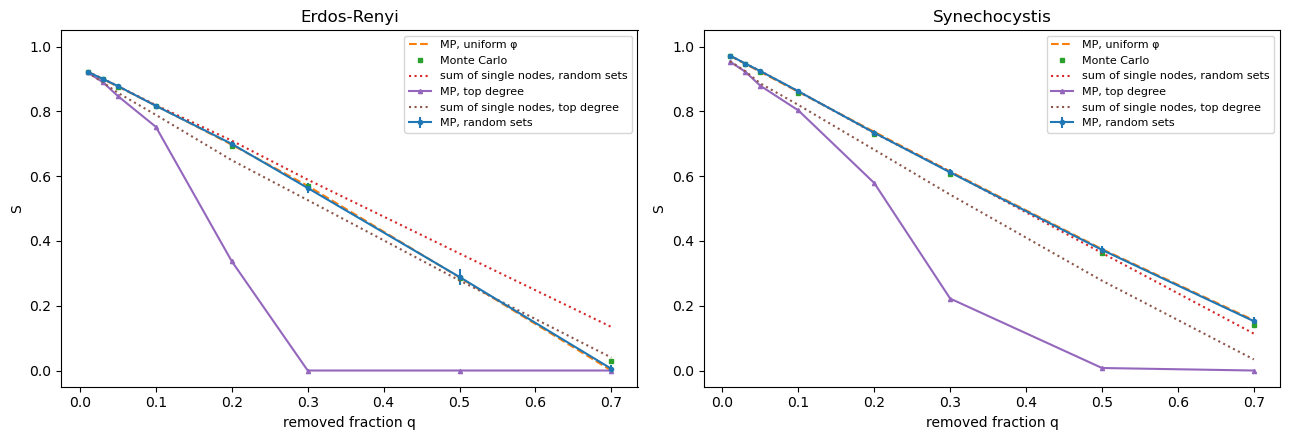

In [10]:
valori_q = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7]
rng_4 = np.random.default_rng(4)
righe = []
for nome in ["Erdos-Renyi", "Synechocystis"]:
    g, struttura = reti[nome], strutture[nome]
    nodi = struttura[1]
    N = len(nodi)
    S_1, S_on, S_off, _, _ = impatto_nodi(g, 1.0, struttura)
    D_1 = S_on - S_off
    per_grado = np.argsort([-gradi[nome][n] for n in nodi])
    str_mc = struttura_mc(g)
    for q in valori_q:
        n_rim = int(round(q * N))
        S_set, somma = [], []
        for _ in range(20):
            scelti = rng_4.choice(N, n_rim, replace=False)
            phi_n = np.ones(N)
            phi_n[scelti] = 0.0
            S_set.append(message_passing_veloce(g, dict(zip(nodi, phi_n)), struttura=struttura)[0])
            somma.append(S_1 - D_1[scelti].sum())
        phi_n = np.ones(N)
        phi_n[per_grado[:n_rim]] = 0.0
        righe.append({"network": nome, "q": q, "phi": 1 - q, "MP random sets": np.mean(S_set), "std sets": np.std(S_set),
                      "MP uniform phi": message_passing_veloce(g, 1 - q, struttura=struttura)[0],
                      "MC": np.mean([mc_1run_veloce(g, 1 - q, rng_4, str_mc) for _ in range(200)]),
                      "sum, random sets": np.mean(somma),
                      "MP, top degree": message_passing_veloce(g, dict(zip(nodi, phi_n)), struttura=struttura)[0],
                      "sum, top degree": S_1 - D_1[per_grado[:n_rim]].sum()})
molti = pd.DataFrame(righe)
molti.to_csv(cartella_ris / "molti_nodi.csv", index=False)
display(molti.round(4))

fig, assi = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (nome, t) in zip(assi, molti.groupby("network", sort=False)):
    ax.errorbar(t["q"], t["MP random sets"], yerr=t["std sets"], fmt="o-", ms=3, label="MP, random sets")
    ax.plot(t["q"], t["MP uniform phi"], "--", label="MP, uniform φ")
    ax.plot(t["q"], t["MC"], "s", ms=3, label="Monte Carlo")
    ax.plot(t["q"], t["sum, random sets"], ":", label="sum of single nodes, random sets")
    ax.plot(t["q"], t["MP, top degree"], "^-", ms=3, label="MP, top degree")
    ax.plot(t["q"], t["sum, top degree"], ":", label="sum of single nodes, top degree")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("removed fraction q")
    ax.set_ylabel("S")
    ax.set_title(nome)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Comment on section 4

**Random sets.** Message passing on random sets gives on average the same `S` as uniform `φ`, and both agree with Monte Carlo within 0.01, except on Erdős-Rényi at `q = 0.7`, close to its threshold (0.028 against 0.005). The sum of the single-node effects `S(1) − Σ D_i` works for random sets up to `q = 0.2` on Erdős-Rényi and `q = 0.5` on Synechocystis (within 0.01); beyond that it overestimates `S`.

**Highest-degree nodes.** For the nodes of largest degree the sum fails much earlier: at `q = 0.2` the true `S` is 0.34 on Erdős-Rényi and 0.58 on Synechocystis, while the sum predicts 0.65 and 0.68; at `q = 0.3` the true `S` is 0 and 0.22 against 0.53 and 0.54. When one hub fails, the other hubs reroute its paths; when they fail together, the alternatives are gone.

**Consequence.** The importance of a set of nodes is not the sum of the importances of its nodes: important nodes overlap and depend on each other. What we protect must be judged as a set, with `S` computed on the whole set.

## Conclusions

- `D_i = S_on − S_off = ∂S/∂φ_i` measures the impact of one node at fixed `φ`; the threshold shift `Δφ_c` does not tell the nodes apart (section 3).
- On the protein networks the nodes with the largest indirect damage are bridges more than hubs: betweenness finds them better than degree (section 1).
- Message passing ranks the nodes as Monte Carlo does, but near the threshold it gets the size of the impact of the important nodes wrong: too large between the two thresholds, too small just above the Monte Carlo one (section 2, Synechocystis).
- Single-node effects add up for random sets, not for the most important nodes, which depend on each other: a set of nodes to protect has to be evaluated as a set (section 4).